# NEC / DINN dengue baselines

Fits cumulative dengue cases (`Itot`) under the **NPC protocol**: train on the
calibration outbreak, evaluate the independent projection outbreak as hold-out.

Two PINN-style models share the same physics and loss:

- **DINN** - a single `MLP(t) -> 8 log1p states`; the 7 ODE parameters are
  trainable (`nn.Parameter`, sigmoid-bounded), `mu_h` fixed at 0.0004.
- **NEC** - adds a calibration head `baseline features -> 7 params` feeding the
  same emulation MLP; gradient flows through both nets.

Physics: full mosquito-human RHS (frequency-dependent transmission with
susceptible births); states and residuals live in log space. Loss =
`MSE(log1p Itot) + 3.0 * residual_MSE` on the calibration grid only - no
gradient from projection.

## Setup

Imports, paths, and plotting helpers. Run this once. Requires the `dinn` conda
environment (torch / scipy / pandas).

In [24]:
from pathlib import Path
import sys
import importlib

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "baseline_experiments.py").exists():
    PROJECT_DIR = PROJECT_DIR / "nec_dinns"
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

import baseline_experiments as be
be = importlib.reload(be)
from baseline_experiments import (
    BaselineConfig,
    default_output_dir,
    discover_regions,
    run_all_baseline_table,
    run_real_experiment,
)

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

CITY_REGIONS = ["bello", "iquitos", "sanjuan"]
COUNTRY_REGIONS = ["cam", "phi", "vn"]


def r2_table_from_predictions(predictions_csv: Path) -> pd.DataFrame:
    """Per region/model/split R^2 of Itot, computed from the predictions CSV."""
    if not predictions_csv.exists():
        print(f"No prediction CSV at {predictions_csv}. Run the sweep first.")
        return pd.DataFrame()
    preds = pd.read_csv(predictions_csv)
    rows = []
    for (region, model, split), g in preds.groupby(["region", "model", "split"]):
        y, yhat = g["observed"].to_numpy(float), g["predicted"].to_numpy(float)
        ss_res = float(np.sum((y - yhat) ** 2))
        ss_tot = float(np.sum((y - y.mean()) ** 2))
        r2 = 1.0 - ss_res / ss_tot if ss_tot > 1e-12 else float("nan")
        rows.append({"region": region, "model": model, "split": split, "r2": r2})
    return (pd.DataFrame(rows)
            .pivot_table(index=["region", "model"], columns="split", values="r2"))


def plot_training_loss_curves(loss_history_csv: Path) -> None:
    if not loss_history_csv.exists():
        print(f"No loss history CSV at {loss_history_csv}. Run the sweep first.")
        return
    hist = pd.read_csv(loss_history_csv)
    required = {"region", "model", "epoch", "loss_data", "loss_phys", "loss_total"}
    if not required.issubset(hist.columns):
        print("Loss history missing columns:", sorted(required - set(hist.columns)))
        return
    combos = (hist[["region", "model"]].drop_duplicates()
              .sort_values(["region", "model"]).to_records(index=False).tolist())
    ncols = 3
    nrows = (len(combos) + ncols - 1) // ncols
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.4 * ncols, 3.8 * nrows), squeeze=False)
    styles = {"loss_data": ("Data loss", "C0"), "loss_phys": ("Physics loss", "C1"),
              "loss_total": ("Total loss", "C3")}
    for ax, (region, model) in zip(axes.ravel(), combos):
        sub = hist[hist["region"].eq(region) & hist["model"].eq(model)].sort_values("epoch")
        label = sub["region_label"].iloc[0] if "region_label" in sub.columns else region
        for col, (lab, color) in styles.items():
            ax.plot(sub["epoch"], sub[col], lw=1.4, color=color, label=lab)
        ax.set_title(f"{label} - {model.upper()}")
        ax.set_xlabel("Epoch"); ax.set_ylabel("Loss"); ax.set_yscale("log"); ax.grid(alpha=0.25)
    for ax in axes.ravel()[len(combos):]:
        ax.axis("off")
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.suptitle("Training losses", y=0.995)
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.965), ncol=3, frameon=False)
    fig.tight_layout(rect=(0, 0, 1, 0.93)); plt.show()

In [25]:
REGIONS = discover_regions()
MODEL_TYPES = ("dinn", "nec")
EPOCHS = 4000             # match the NPC paper training budget
SEEDS = (0, 1, 2, 3, 4)   # multi-seed ensemble

RESULTS_CSV = default_output_dir() / "baseline_results.csv"
PREDICTIONS_CSV = default_output_dir() / "baseline_predictions.csv"
LOSS_HISTORY_CSV = default_output_dir() / "baseline_loss_history.csv"

if not REGIONS:
    raise RuntimeError(
        "No NPC data found under data_piml/npc. Place data_cali.csv and "
        "data_proj.csv under data_piml/npc/<region>/."
    )

print("regions:", REGIONS)
print("seeds  :", SEEDS)
print("results ->", RESULTS_CSV)


regions: ['bello', 'cam', 'iquitos', 'phi', 'sanjuan', 'vn']
seeds  : (0, 1, 2, 3, 4)
results -> /Users/linhngo/Downloads/Work/PINNs/NEC/nec_dinns/outputs/baseline_results.csv


## Smoke test

Two epochs confirm the DINN residual path and the NEC solver-projection path.
The NEC assertion verifies projection no longer uses the time-only MLP.


In [ ]:
smoke_cfg = BaselineConfig(epochs=2, log_every=1)
smoke = run_real_experiment("iquitos", "dinn", smoke_cfg, seed=0, verbose=True)
print({k: smoke[k] for k in ("seed", "loss_data_final", "loss_phys_final", "epochs_run", "train_seconds")})
print("DINN cal  R2:", round(smoke["cal_metrics"]["r2"], 4))
print("DINN proj R2:", round(smoke["proj_metrics"]["r2"], 4))
print("params :", {k: round(v, 4) for k, v in smoke["params_final"].items()})

nec_smoke = run_real_experiment("bello", "nec", smoke_cfg, seed=0, verbose=False)
print("NEC cal  R2:", round(nec_smoke["cal_metrics"]["r2"], 4))
print("NEC proj R2:", round(nec_smoke["proj_metrics"]["r2"], 4))
# NEC projects with the shared emulator MLP (no ODE solver, no IC head).
print("NEC projection method:", nec_smoke["proj_method"])

## Full DINN / NEC sweep

Trains every discovered region for DINN and NEC and writes the result,
prediction, and loss-history CSVs to `outputs/`. Set `RUN_FULL_SWEEP = False`
to load the last saved CSVs without retraining.

In [27]:
RUN_FULL_SWEEP = True

full_cfg = BaselineConfig(epochs=EPOCHS, log_every=500)

if RUN_FULL_SWEEP:
    results = run_all_baseline_table(
        regions=REGIONS,
        model_types=MODEL_TYPES,
        config=full_cfg,
        seeds=SEEDS,
        output_csv=RESULTS_CSV,
        prediction_csv=PREDICTIONS_CSV,
        loss_history_csv=LOSS_HISTORY_CSV,
        verbose=True,
    )
elif RESULTS_CSV.exists():
    results = pd.read_csv(RESULTS_CSV)
else:
    results = pd.DataFrame()
    print("No saved results yet. Set RUN_FULL_SWEEP = True to train.")

display(results)



=== Bello / DINN | 5 seeds ===
  ep     0  data=2.130e+01  phys=2.874e+01
  ep   500  data=6.038e-03  phys=7.332e-03
  ep  1000  data=4.054e-03  phys=3.902e-03
  ep  1500  data=2.903e-03  phys=2.484e-03
  ep  2000  data=2.262e-03  phys=1.937e-03
  ep  2500  data=1.966e-03  phys=1.743e-03
  ep  3000  data=1.746e-03  phys=1.663e-03
  ep  3500  data=1.567e-03  phys=1.616e-03
  ep  3999  data=1.477e-03  phys=1.584e-03
  ep     0  data=2.039e+01  phys=2.972e+01
  ep   500  data=1.289e-02  phys=7.508e-03
  ep  1000  data=2.454e-03  phys=2.029e-03
  ep  1500  data=4.294e-03  phys=1.711e-03
  ep  2000  data=1.880e-03  phys=1.668e-03
  ep  2500  data=1.686e-03  phys=1.641e-03
  ep  3000  data=1.599e-03  phys=1.616e-03
  ep  3500  data=1.508e-03  phys=1.593e-03
  ep  3999  data=1.458e-03  phys=1.580e-03
  ep     0  data=2.355e+01  phys=4.504e+01
  ep   500  data=1.390e-02  phys=8.464e-03
  ep  1000  data=2.400e-03  phys=1.679e-03
  ep  1500  data=2.153e-03  phys=1.618e-03
  ep  2000  data=1.867

,region,model,n_seeds,mse_normalized,train_seconds,mse_normalized_mean,mse_normalized_std,r2_proj_mean,r2_proj_std,train_seconds_mean
0,bello,dinn,5,0.012812,13.127930,0.012812,0.000016,0.886773,0.000138,13.127930
1,bello,nec,5,0.012817,13.802615,0.012817,0.000015,0.886729,0.000137,13.802615
2,cam,dinn,5,0.123055,12.682125,0.123055,0.000008,0.015807,0.000065,12.682125
3,cam,nec,5,0.123065,14.001605,0.123065,0.000023,0.015721,0.000180,14.001605
4,iquitos,dinn,5,0.039907,12.608501,0.039907,0.000111,0.712502,0.000799,12.608501
5,iquitos,nec,5,0.040005,13.931658,0.040005,0.000291,0.711802,0.002094,13.931658
6,phi,dinn,5,0.011962,12.518215,0.011962,0.000127,0.894584,0.001116,12.518215
7,phi,nec,5,0.012020,13.335789,0.012020,0.000136,0.894070,0.001203,13.335789
8,sanjuan,dinn,5,0.018109,12.438598,0.018109,0.000026,0.861503,0.000202,12.438598
9,sanjuan,nec,5,0.018116,13.769938,0.018116,0.000028,0.861443,0.000217,13.769938


## Scores

The results CSV holds the held-out (projection) normalised MSE and the runtime.
The R^2 table is computed from the prediction curves for both splits: `cal`
should be ~1.0, while `proj` is a shape-generalisation check on the independent
outbreak (only required to stay positive).

In [28]:
if results.empty:
    print("No result table loaded yet.")
else:
    display(results.sort_values(["region", "model"]).reset_index(drop=True))

display(r2_table_from_predictions(PREDICTIONS_CSV))

,region,model,n_seeds,mse_normalized,train_seconds,mse_normalized_mean,mse_normalized_std,r2_proj_mean,r2_proj_std,train_seconds_mean
0,bello,dinn,5,0.012812,13.127930,0.012812,0.000016,0.886773,0.000138,13.127930
1,bello,nec,5,0.012817,13.802615,0.012817,0.000015,0.886729,0.000137,13.802615
2,cam,dinn,5,0.123055,12.682125,0.123055,0.000008,0.015807,0.000065,12.682125
3,cam,nec,5,0.123065,14.001605,0.123065,0.000023,0.015721,0.000180,14.001605
4,iquitos,dinn,5,0.039907,12.608501,0.039907,0.000111,0.712502,0.000799,12.608501
5,iquitos,nec,5,0.040005,13.931658,0.040005,0.000291,0.711802,0.002094,13.931658
6,phi,dinn,5,0.011962,12.518215,0.011962,0.000127,0.894584,0.001116,12.518215
7,phi,nec,5,0.012020,13.335789,0.012020,0.000136,0.894070,0.001203,13.335789
8,sanjuan,dinn,5,0.018109,12.438598,0.018109,0.000026,0.861503,0.000202,12.438598
9,sanjuan,nec,5,0.018116,13.769938,0.018116,0.000028,0.861443,0.000217,13.769938


split          calibration  projection
region  model                         
bello   dinn      0.999766    0.886798
        nec       0.999751    0.886773
cam     dinn      0.999288    0.015817
        nec       0.999067    0.015732
iquitos dinn      0.998715    0.712573
        nec       0.998815    0.712142
phi     dinn      0.999850    0.894619
        nec       0.999844    0.894116
sanjuan dinn      0.999658    0.861517
        nec       0.999653    0.861468
vn      dinn      0.999503    0.925158
        nec       0.999446    0.924931

## Training loss curves

Per-epoch `loss_data`, `loss_phys`, and `loss_total` (log scale) per region/model.

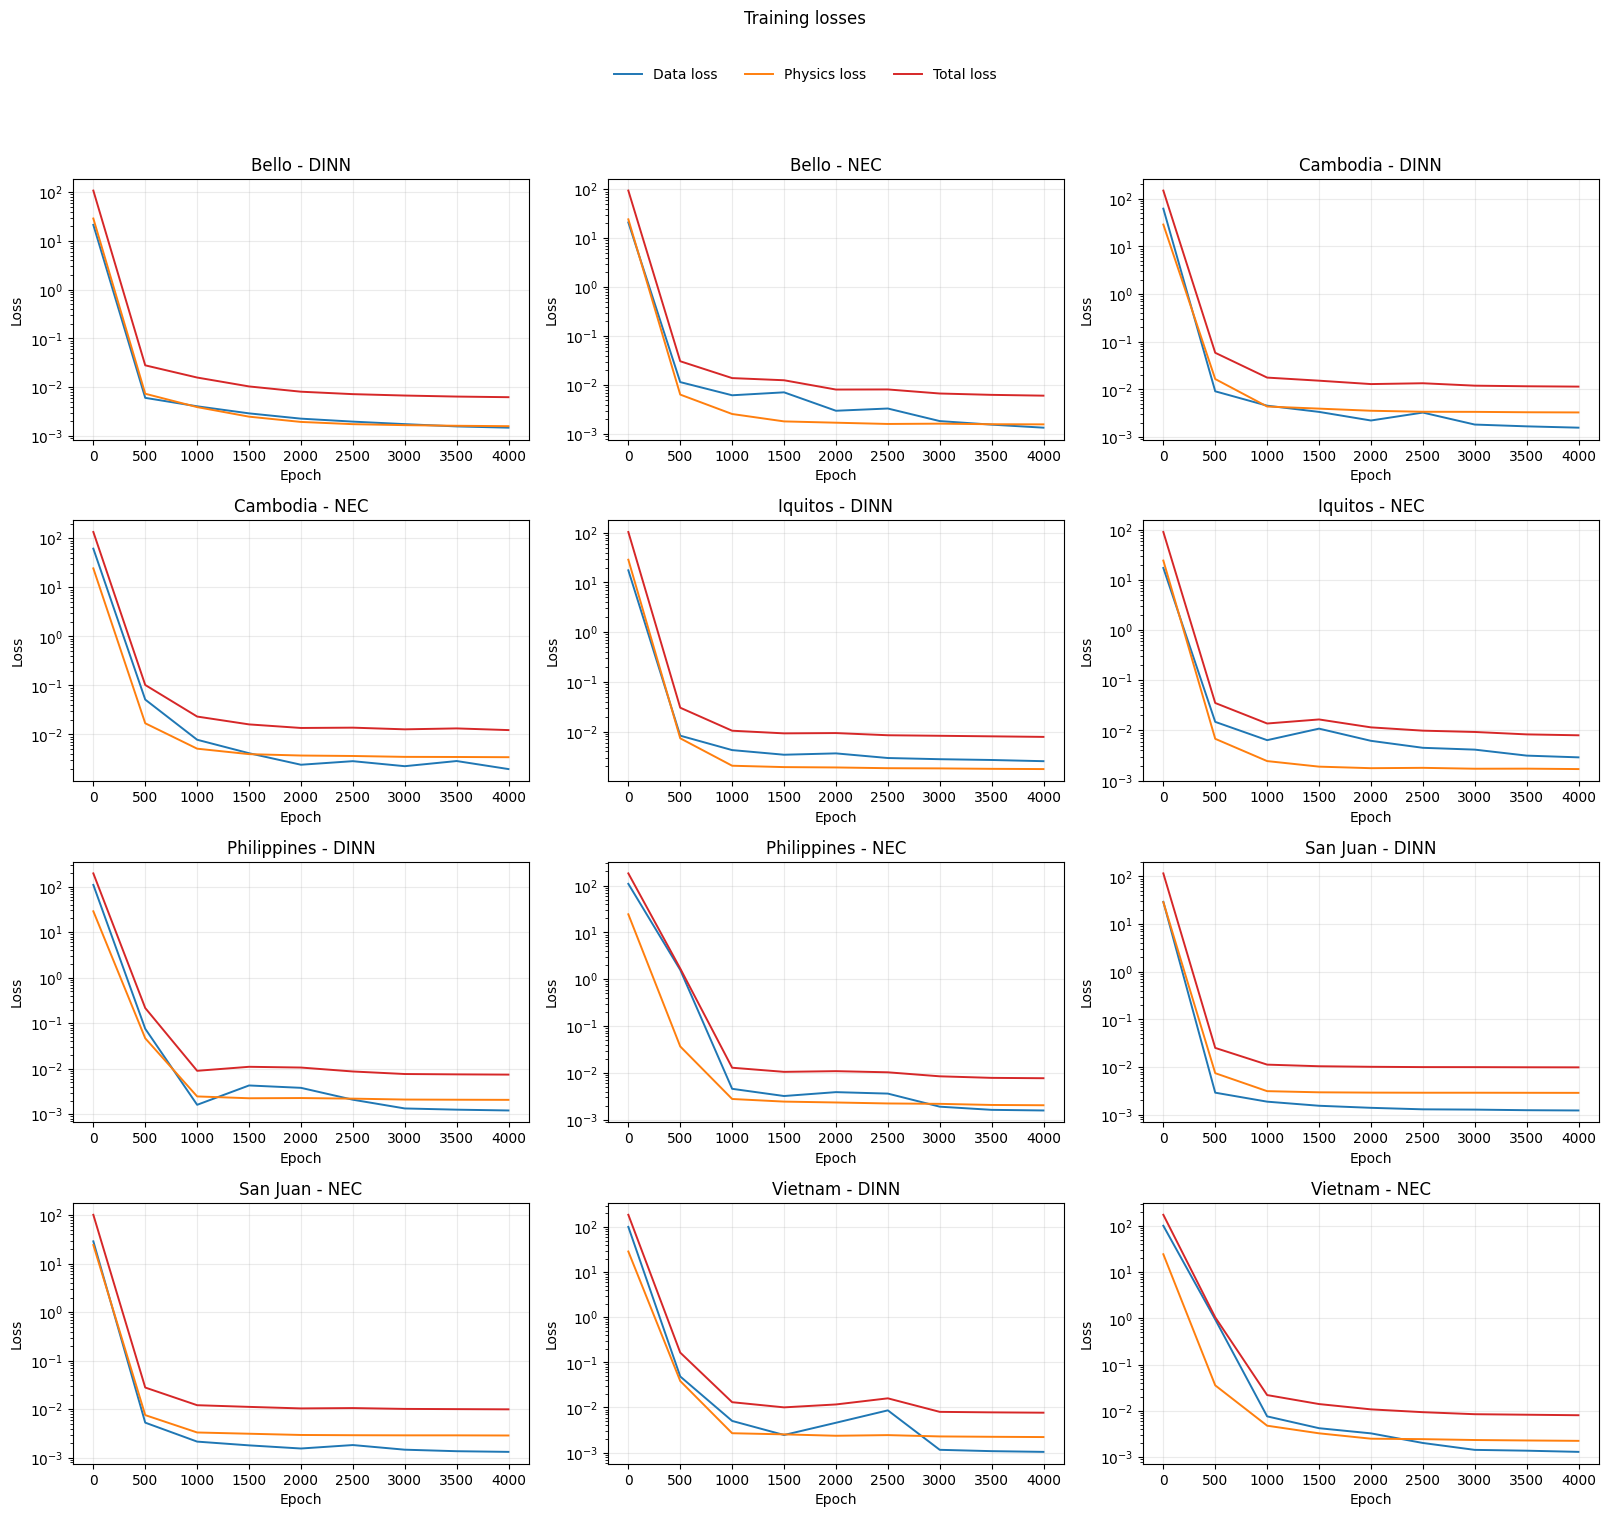

In [29]:
plot_training_loss_curves(LOSS_HISTORY_CSV)

## Score and runtime comparison

Projection `mse_normalized` and `train_seconds` for DINN vs NEC.

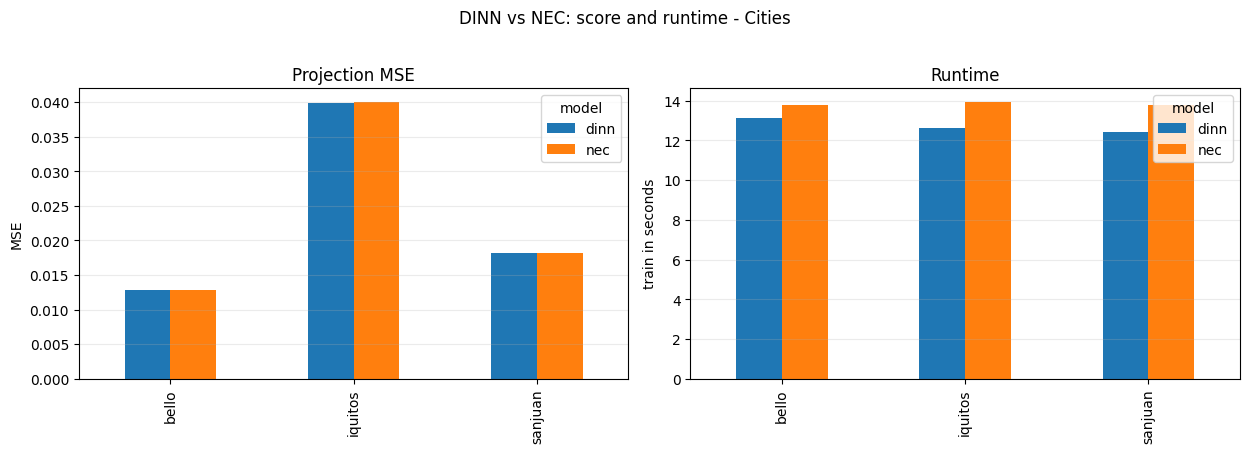

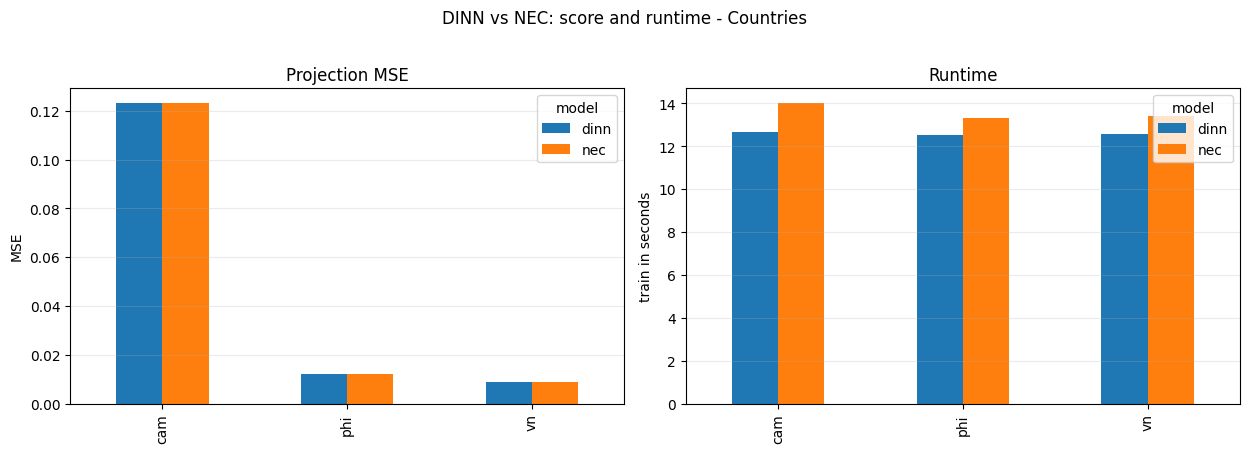

In [37]:
plot_results = results.copy()
if plot_results.empty and RESULTS_CSV.exists():
    plot_results = pd.read_csv(RESULTS_CSV)


def plot_score_runtime_group(group_name: str, regions) -> None:
    plot_regions = [r for r in regions if r in set(plot_results["region"])]
    if not plot_regions:
        print(f"No result rows for {group_name.lower()}.")
        return

    group_results = plot_results[plot_results["region"].isin(plot_regions)]
    fig, axes = plt.subplots(1, 2, figsize=(max(8, 4.2 * len(plot_regions)), 4.4))

    (group_results.pivot_table(index="region", columns="model",
                               values="mse_normalized", aggfunc="mean")
     .reindex(plot_regions).plot(kind="bar", ax=axes[0]))
    axes[0].set_title("Projection MSE")
    axes[0].set_ylabel("MSE"); axes[0].set_xlabel("")
    axes[0].grid(axis="y", alpha=0.25)

    (group_results.drop_duplicates(["region", "model"])
     .pivot_table(index="region", columns="model", values="train_seconds", aggfunc="mean")
     .reindex(plot_regions).plot(kind="bar", ax=axes[1]))
    axes[1].set_title("Runtime"); axes[1].set_ylabel("train in seconds"); axes[1].set_xlabel("")
    axes[1].grid(axis="y", alpha=0.25)

    fig.suptitle(f"DINN vs NEC: score and runtime - {group_name}", y=1.02)
    fig.tight_layout(); plt.show()


if plot_results.empty:
    print("No result table loaded yet.")
else:
    plot_score_runtime_group("Cities", CITY_REGIONS)
    plot_score_runtime_group("Countries", COUNTRY_REGIONS)

## Prediction curves (Itot)

Observed vs predicted cumulative cases for the calibration and projection
outbreaks, grouped by cities and countries.

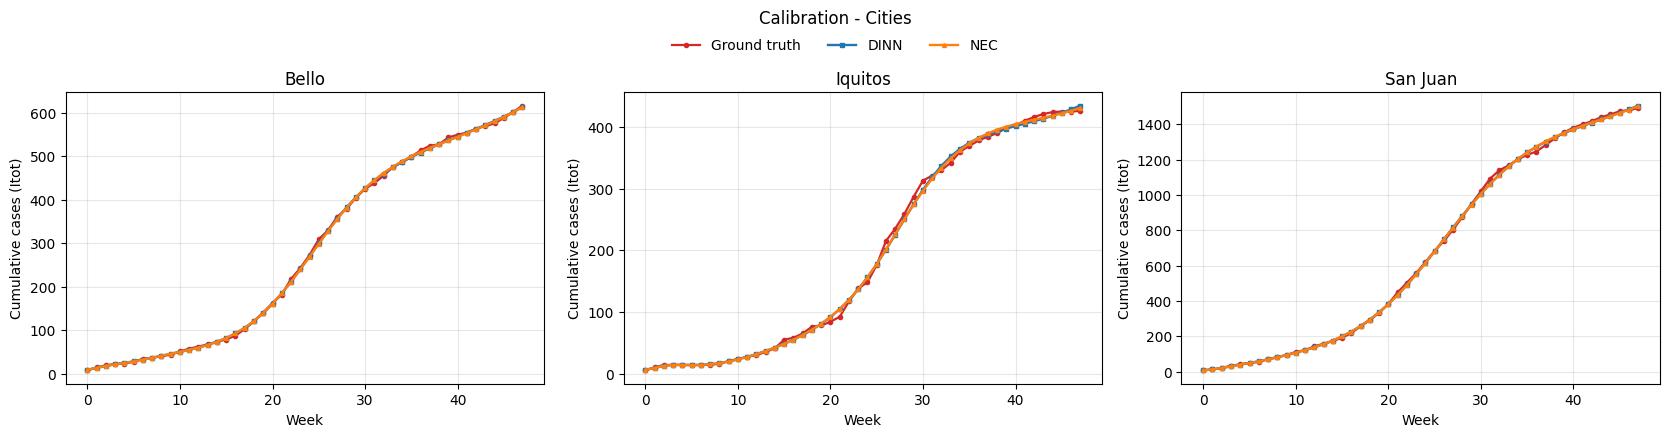

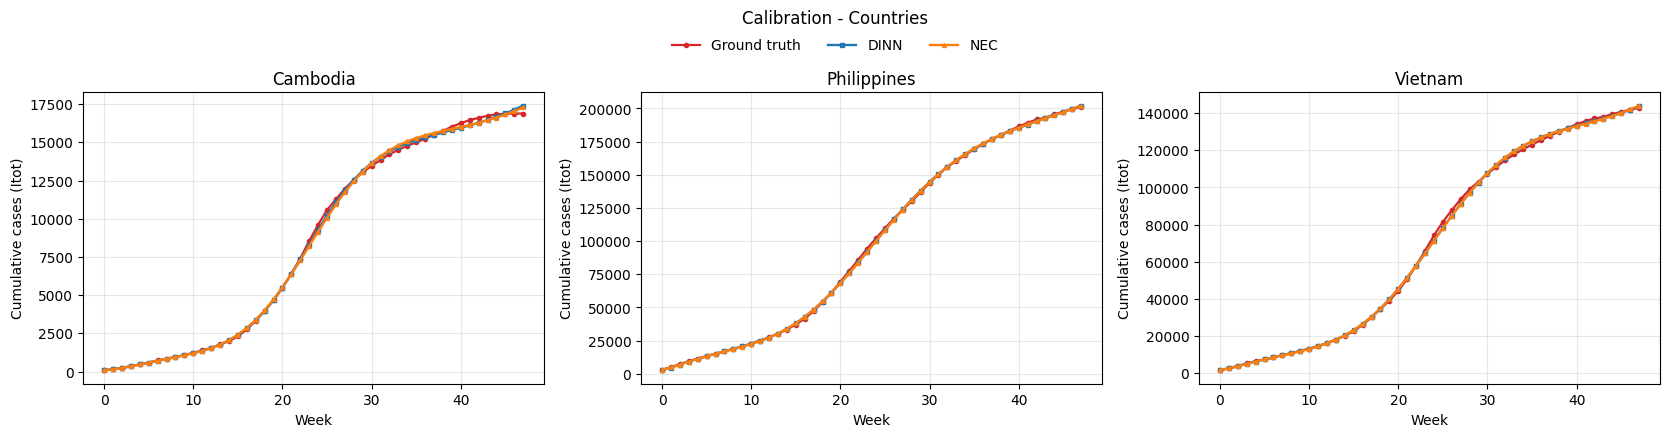

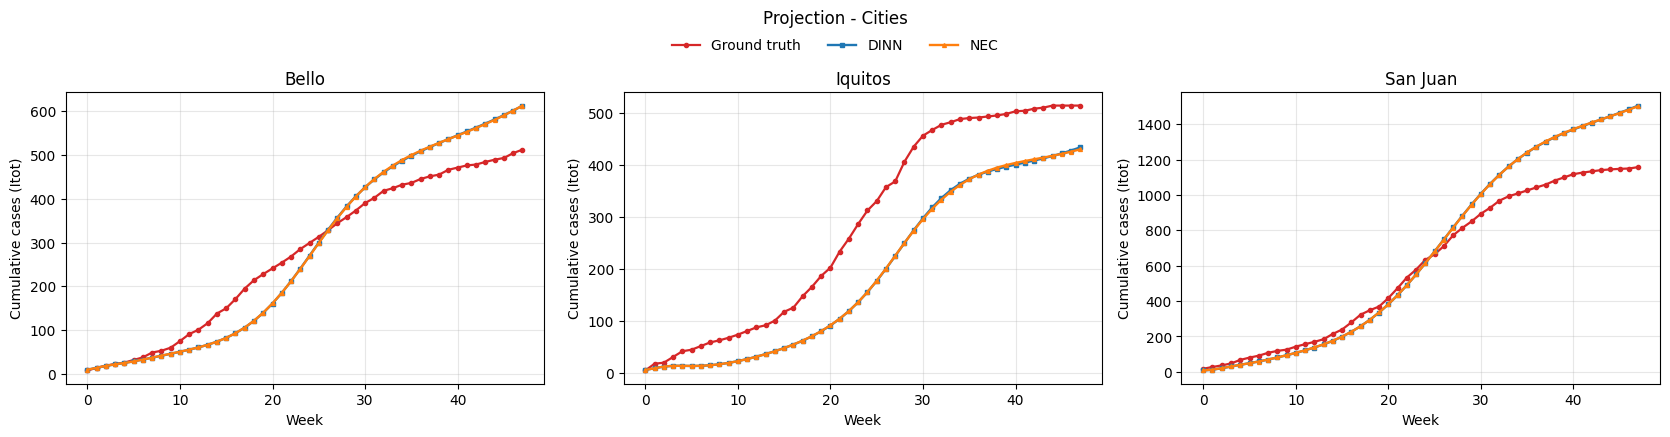

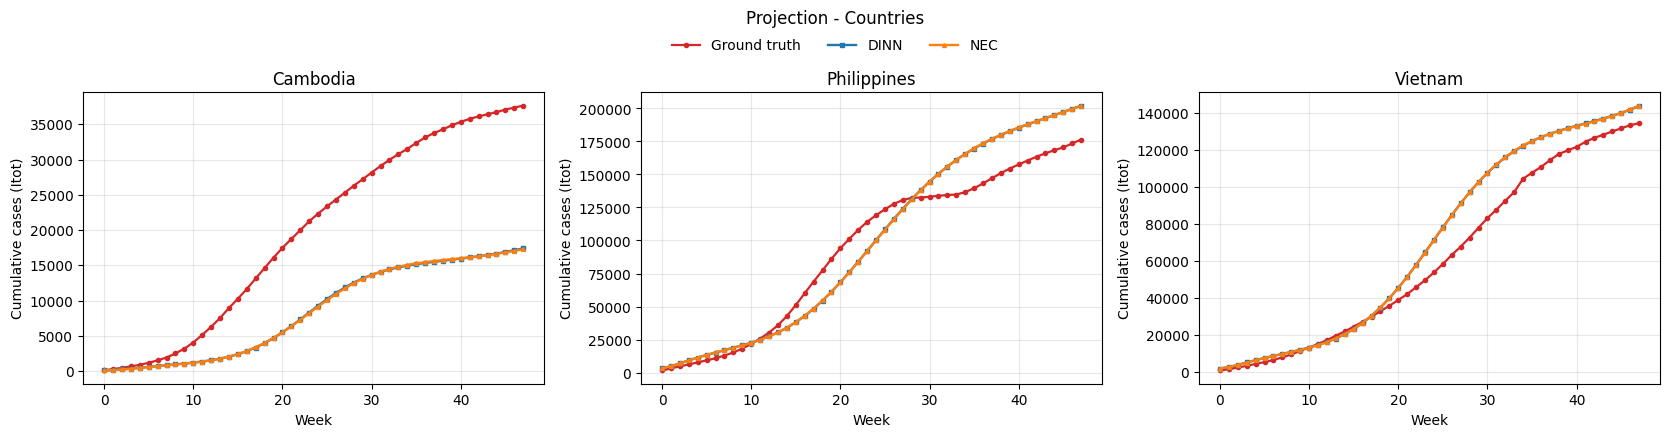

In [32]:
def plot_curves(split: str) -> None:
    if not PREDICTIONS_CSV.exists():
        print(f"No prediction CSV at {PREDICTIONS_CSV}."); return
    preds = pd.read_csv(PREDICTIONS_CSV)
    preds = preds[preds["split"].eq(split) & preds["target"].eq("Itot")]
    styles = {"dinn": ("DINN", "C0", "s"), "nec": ("NEC", "C1", "^")}
    groups = [("Cities", [r for r in CITY_REGIONS if r in set(preds["region"])]),
              ("Countries", [r for r in COUNTRY_REGIONS if r in set(preds["region"])])]
    for group_name, regs in groups:
        if not regs:
            continue
        fig, axes = plt.subplots(1, len(regs), figsize=(5.6 * len(regs), 4.2), squeeze=False)
        for ax, region in zip(axes[0], regs):
            obs = preds[preds["region"].eq(region)]
            if obs.empty:
                ax.axis("off"); continue
            label = obs["region_label"].iloc[0]
            truth = obs.drop_duplicates("t").sort_values("t")
            ax.plot(truth["t"], truth["observed"], color="C3", marker="o", ms=3, lw=1.6,
                    label="Ground truth")
            for model in MODEL_TYPES:
                sub = obs[obs["model"].eq(model)].sort_values("t")
                if sub.empty:
                    continue
                lab, color, marker = styles.get(model, (model.upper(), None, None))
                ax.plot(sub["t"], sub["predicted"], color=color, marker=marker, ms=2.8, lw=1.7,
                        label=lab)
            ax.set_title(label); ax.set_xlabel("Week"); ax.set_ylabel("Cumulative cases (Itot)")
            ax.grid(alpha=0.3)
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.suptitle(f"{split.capitalize()} - {group_name}", y=1.03)
        fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.99),
                   ncol=3, frameon=False)
        fig.tight_layout(); plt.show()


plot_curves("calibration")
plot_curves("projection")

##  figure: cumulative + weekly incidence

Top row: cumulative cases (`Hitotal`). Bottom row: weekly incidence (`Hi`),
derived as the week-over-week difference of the cumulative curve.

`split="calibration"` with the three cities matches the reference layout; the
same function renders `split="projection"` or `regions=COUNTRY_REGIONS`.

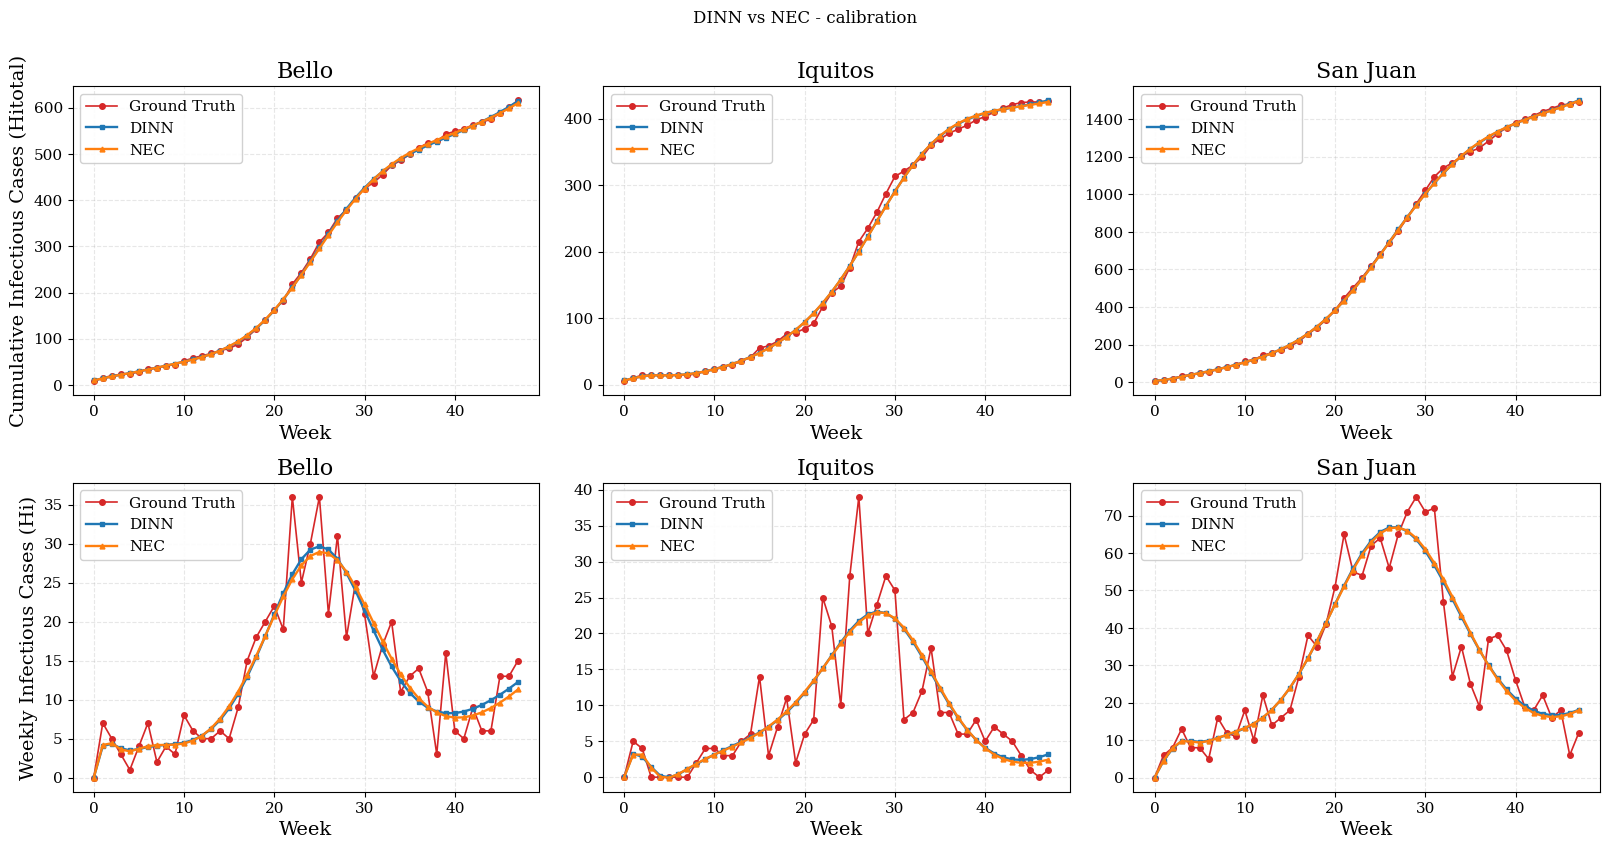

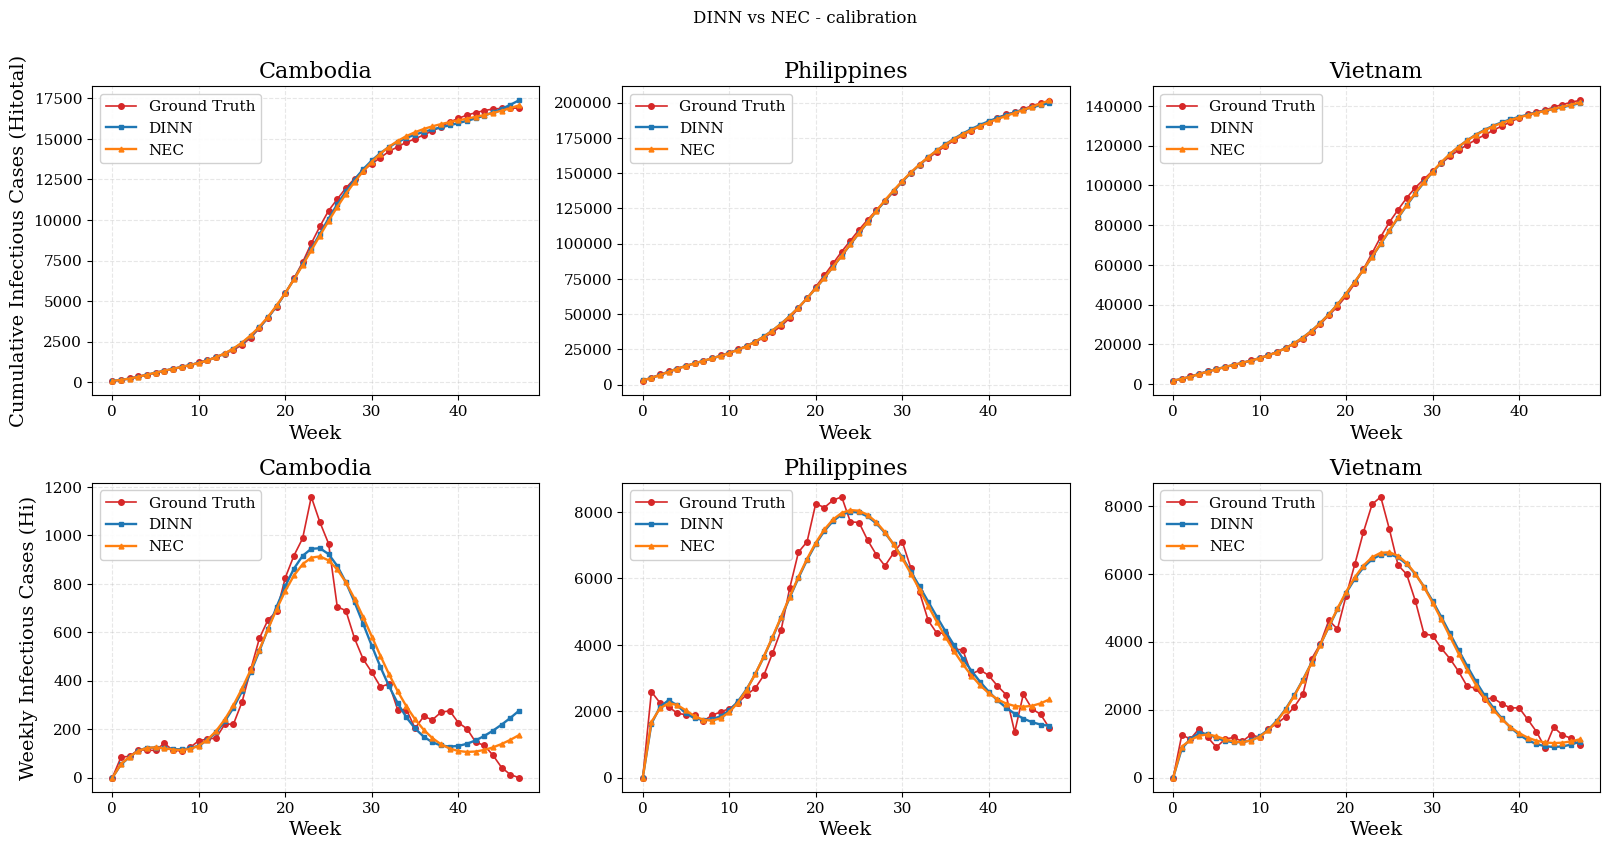

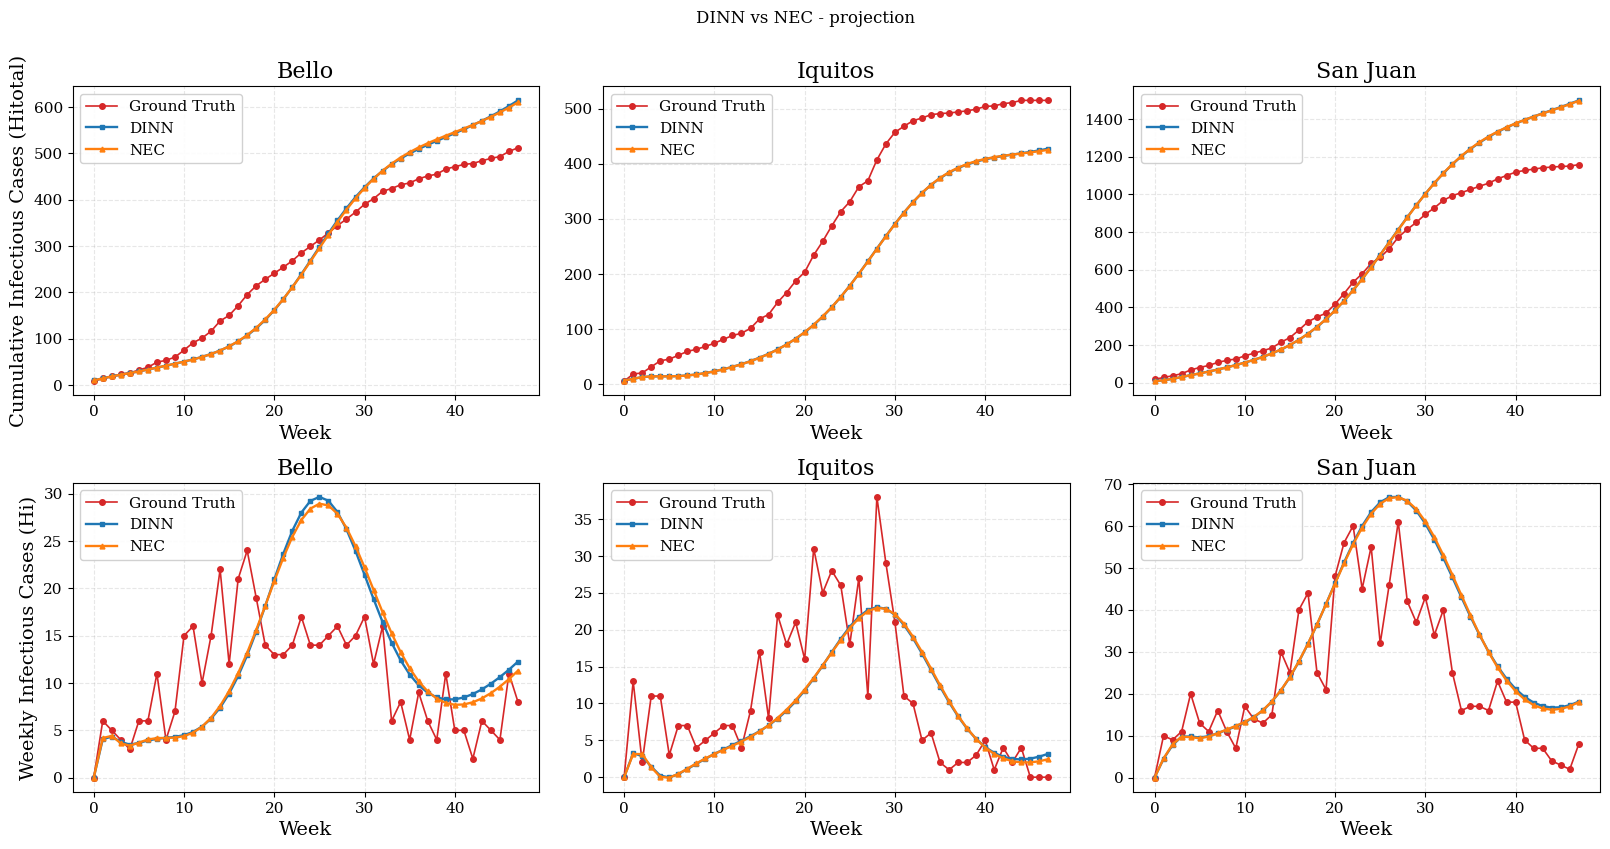

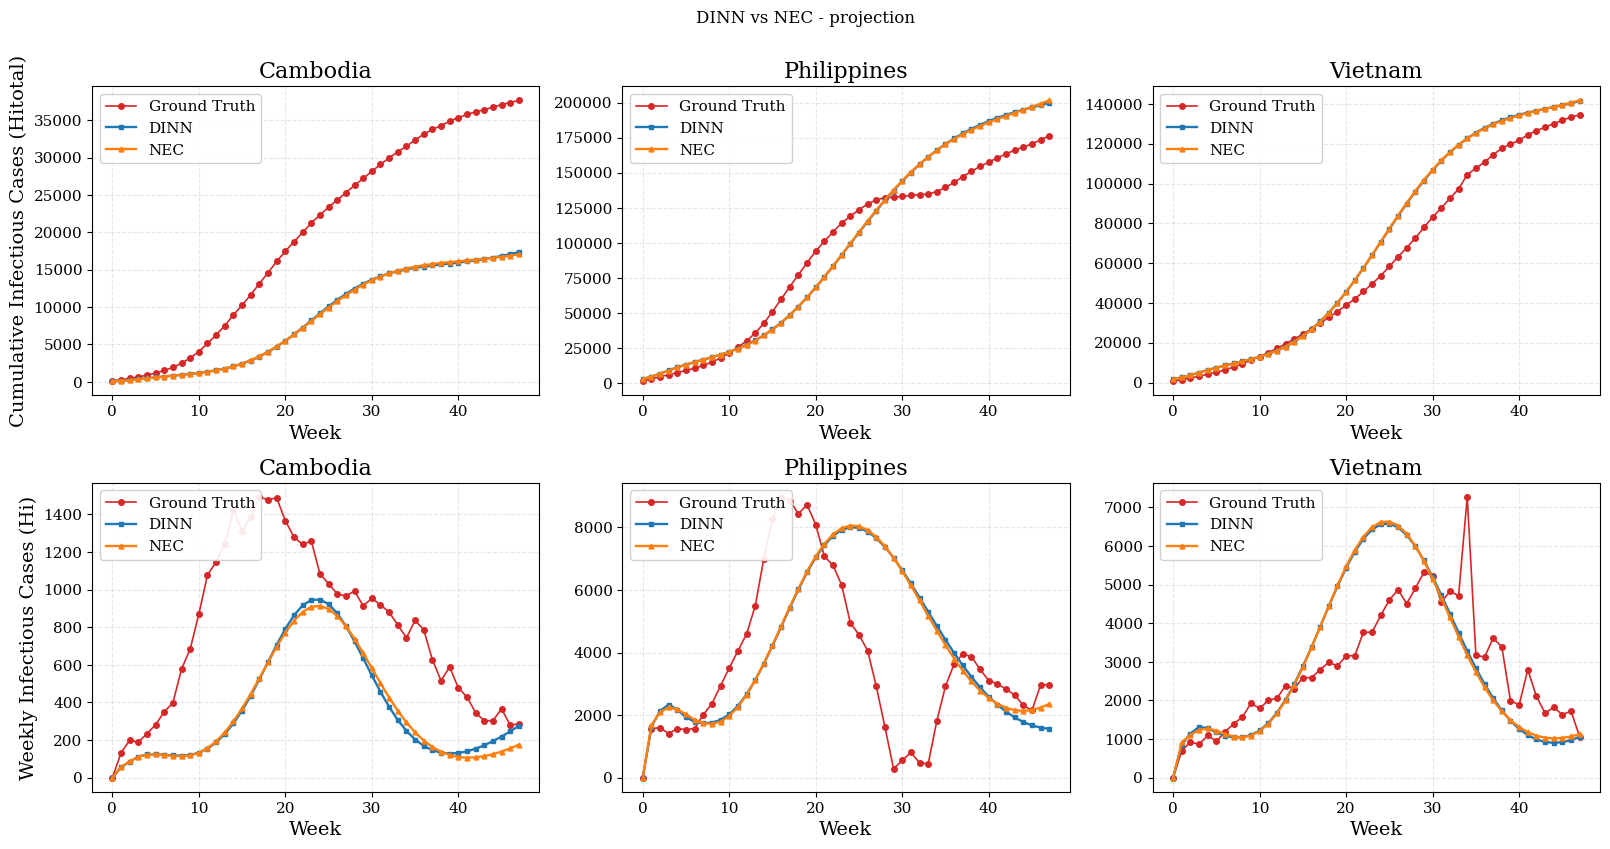

In [ ]:
def weekly_incidence(cum):
    """Weekly new cases from a cumulative series (first difference, week 0 kept)."""
    cum = np.asarray(cum, float)
    return np.diff(cum, prepend=cum[0])


def plot_npc_style(split="calibration", regions=CITY_REGIONS):
    if not PREDICTIONS_CSV.exists():
        print(f"No prediction CSV at {PREDICTIONS_CSV}. Run the sweep first."); return
    df = pd.read_csv(PREDICTIONS_CSV)
    df = df[df["split"].eq(split) & df["target"].eq("Itot")]
    regions = [r for r in regions if r in set(df["region"])]
    if not regions:
        print(f"No rows for split={split!r}."); return

    styles = {
        "truth": dict(color="#d62728", marker="o", ms=4, lw=1.2),
        "dinn": dict(color="#1f77b4", marker="s", ms=3.5, lw=1.7),
        "nec": dict(color="#ff7f0e", marker="^", ms=3.5, lw=1.7),
    }
    names = {"dinn": "DINN", "nec": "NEC"}
    rc = {"font.family": "serif", "mathtext.fontset": "cm",
          "axes.titlesize": 16, "axes.labelsize": 14,
          "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11}

    with plt.rc_context(rc):
        fig, axes = plt.subplots(2, len(regions), figsize=(5.4 * len(regions), 8.4), squeeze=False)
        for col, region in enumerate(regions):
            g = df[df["region"].eq(region)]
            label = g["region_label"].iloc[0]
            truth = g.drop_duplicates("t").sort_values("t")
            t = truth["t"].to_numpy(); obs = truth["observed"].to_numpy(float)
            ax_c, ax_w = axes[0, col], axes[1, col]
            ax_c.plot(t, obs, label="Ground Truth", **styles["truth"])
            ax_w.plot(t, weekly_incidence(obs), label="Ground Truth", **styles["truth"])
            for model in MODEL_TYPES:
                sub = g[g["model"].eq(model)].sort_values("t")
                if sub.empty:
                    continue
                pred = sub["predicted"].to_numpy(float)
                st = styles.get(model, dict(lw=1.7))
                ax_c.plot(sub["t"], pred, label=names.get(model, model.upper()), **st)
                ax_w.plot(sub["t"], weekly_incidence(pred), label=names.get(model, model.upper()), **st)
            ax_c.set_title(label); ax_w.set_title(label)
            ax_c.set_xlabel("Week"); ax_w.set_xlabel("Week")
            if col == 0:
                ax_c.set_ylabel("Cumulative Infectious Cases (Hitotal)")
                ax_w.set_ylabel("Weekly Infectious Cases (Hi)")
            for ax in (ax_c, ax_w):
                ax.grid(True, ls="--", alpha=0.3); ax.legend(loc="upper left", framealpha=0.9)
        fig.suptitle(f"DINN vs NEC - {split}", y=1.005)
        fig.tight_layout(); plt.show()


# Calibration (model fit) -- cities then countries
plot_npc_style(split="calibration", regions=CITY_REGIONS)
plot_npc_style(split="calibration", regions=COUNTRY_REGIONS)

# Projection (held-out outbreak) -- cities then countries
plot_npc_style(split="projection", regions=CITY_REGIONS)
plot_npc_style(split="projection", regions=COUNTRY_REGIONS)

## Prediction uncertainty bands (multi-seed)

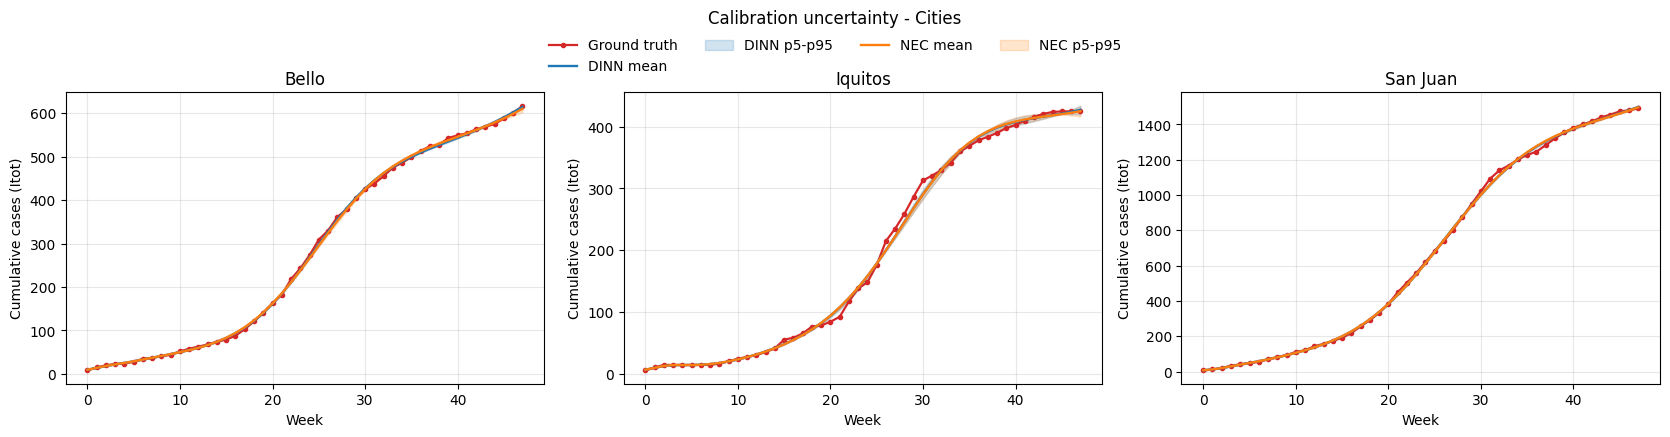

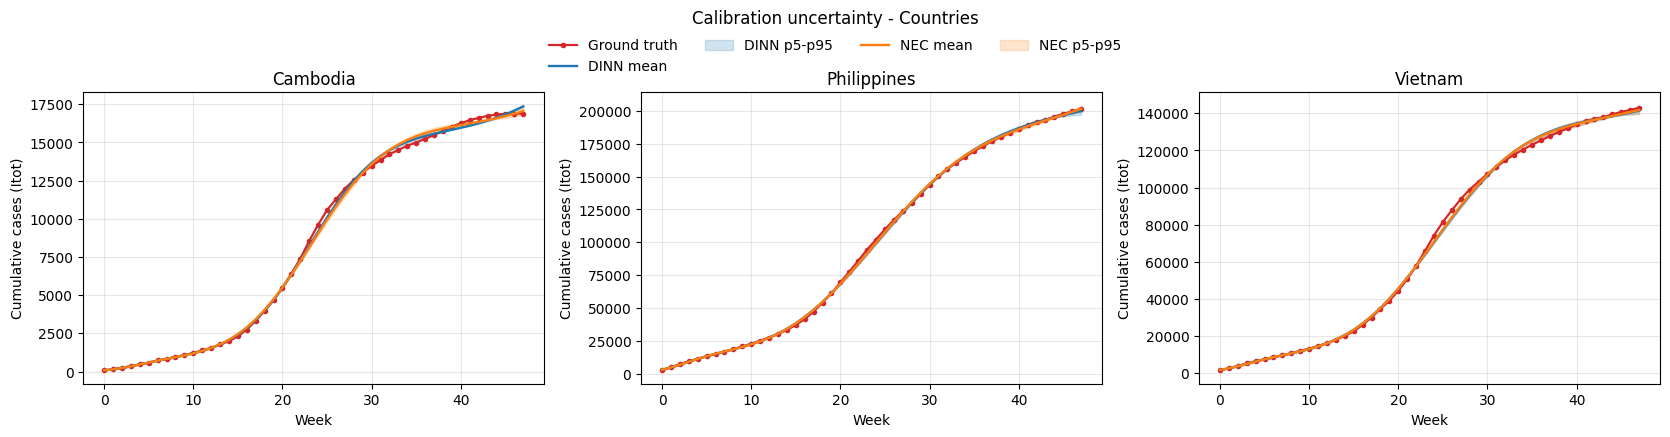

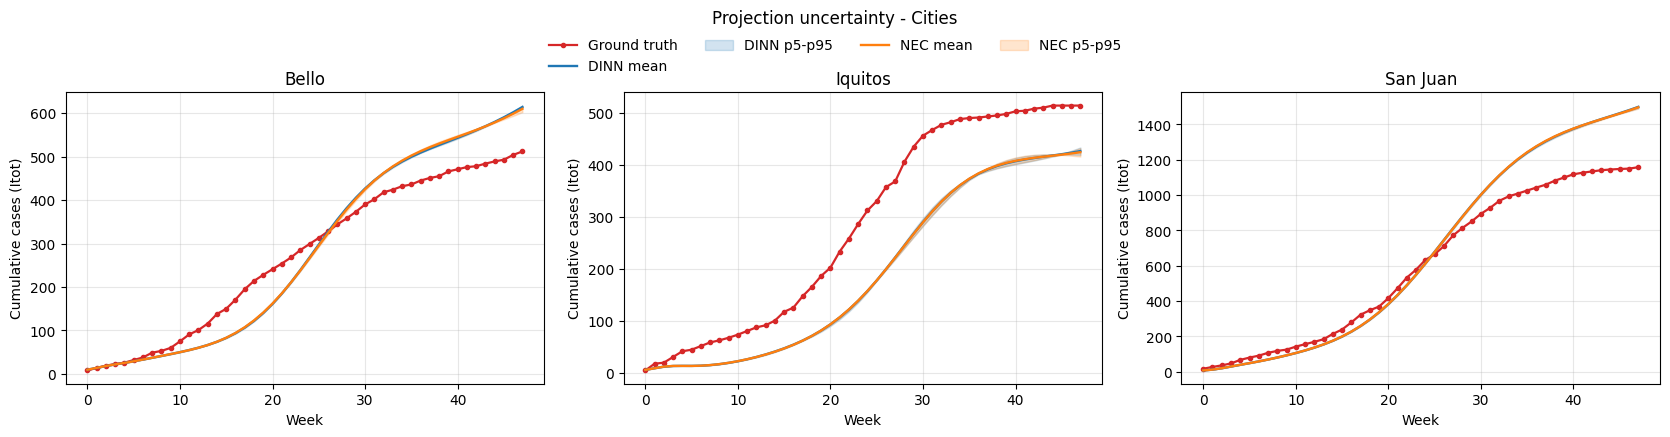

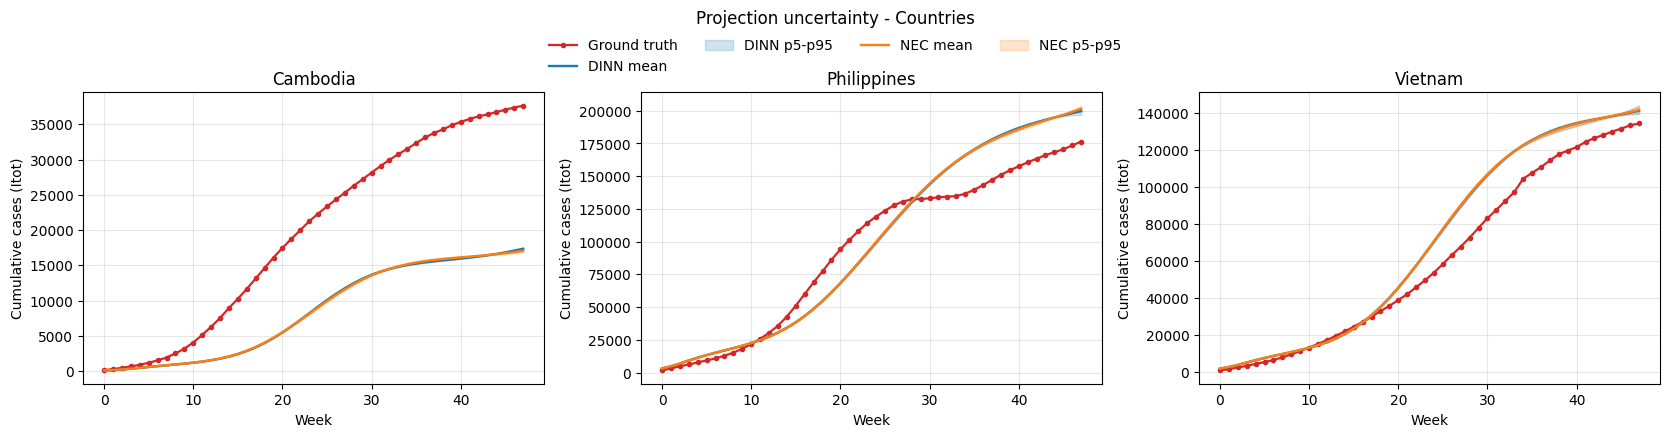

In [ ]:
def plot_uncertainty_bands(split: str) -> None:
    """Mean prediction with a [p5, p95] band across seeds vs ground truth."""
    if not PREDICTIONS_CSV.exists():
        print(f"No prediction CSV at {PREDICTIONS_CSV}."); return
    preds = pd.read_csv(PREDICTIONS_CSV)
    preds = preds[preds["split"].eq(split) & preds["target"].eq("Itot")]
    if preds.empty:
        print(f"No {split} predictions found."); return
    has_band = {"predicted_mean", "predicted_p5", "predicted_p95"}.issubset(preds.columns)
    styles = {"dinn": ("DINN", "C0"), "nec": ("NEC", "C1")}
    groups = [("Cities", [r for r in CITY_REGIONS if r in set(preds["region"])]),
              ("Countries", [r for r in COUNTRY_REGIONS if r in set(preds["region"])])]
    for group_name, regs in groups:
        if not regs:
            continue
        fig, axes = plt.subplots(1, len(regs), figsize=(5.6 * len(regs), 4.2), squeeze=False)
        for ax, region in zip(axes[0], regs):
            obs = preds[preds["region"].eq(region)]
            label = obs["region_label"].iloc[0]
            truth = obs.drop_duplicates("t").sort_values("t")
            ax.plot(truth["t"], truth["observed"], color="C3", marker="o", ms=3, lw=1.6,
                    label="Ground truth")
            for model, (lab, color) in styles.items():
                sub = obs[obs["model"].eq(model)].sort_values("t")
                if sub.empty:
                    continue
                mean_col = "predicted_mean" if has_band else "predicted"
                ax.plot(sub["t"], sub[mean_col], color=color, lw=1.7, label=f"{lab} mean")
                if has_band:
                    ax.fill_between(sub["t"], sub["predicted_p5"], sub["predicted_p95"],
                                    color=color, alpha=0.2, label=f"{lab} p5-p95")
            ax.set_title(label); ax.set_xlabel("Week"); ax.set_ylabel("Cumulative cases (Itot)")
            ax.grid(alpha=0.3)
        handles, labels = axes[0, 0].get_legend_handles_labels()
        fig.suptitle(f"{split.capitalize()} uncertainty - {group_name}", y=1.03)
        fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.99),
                   ncol=4, frameon=False)
        fig.tight_layout(); plt.show()


plot_uncertainty_bands("calibration")
plot_uncertainty_bands("projection")


## Comparison with NPC paper

In [ ]:
# NPC paper MSE (Pham et al. 2026, Tables 2 & 3): city avg ~0.0068, country avg ~0.0061.
NPC_PAPER_MSE = {
    "bello": 0.0068, "iquitos": 0.0068, "sanjuan": 0.0068,
    "cam": 0.0061, "phi": 0.0061, "vn": 0.0061,
}

if results.empty:
    print("No results to compare. Run the sweep first.")
else:
    comparison = results.copy()
    comparison["npc_paper_mse"] = comparison["region"].map(NPC_PAPER_MSE)
    comparison["gap_x"] = comparison["mse_normalized_mean"] / comparison["npc_paper_mse"]
    cols = ["region", "model", "mse_normalized_mean", "mse_normalized_std",
            "npc_paper_mse", "gap_x"]
    display(comparison[cols].sort_values(["region", "model"]).reset_index(drop=True))


,region,model,mse_normalized_mean,mse_normalized_std,npc_paper_mse,gap_x
0,bello,dinn,0.012832,0.000027,0.0068,1.887032
1,bello,nec,0.012837,0.000022,0.0068,1.887752
2,cam,dinn,0.123119,0.000080,0.0061,20.183367
3,cam,nec,0.123076,0.000067,0.0061,20.176452
4,iquitos,dinn,0.040256,0.000364,0.0068,5.919995
5,iquitos,nec,0.040251,0.000316,0.0068,5.919315
6,phi,dinn,0.012263,0.000245,0.0061,2.010326
7,phi,nec,0.012135,0.000098,0.0061,1.989348
8,sanjuan,dinn,0.018145,0.000049,0.0068,2.668348
9,sanjuan,nec,0.018153,0.000021,0.0068,2.669597
